In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 140)
PATH_NASABAH = 'nasabah_raw.csv'
PATH_EKSTERNAL = 'data_kredit_eksternal.csv'

## a. Pemeriksaan Awal & Penghapusan Duplikat

In [2]:
df = pd.read_csv(PATH_NASABAH)
df_ext = pd.read_csv(PATH_EKSTERNAL)

print('Dimensi nasabah_raw      :', df.shape)
print('Dimensi data_kredit_eks. :', df_ext.shape)
print()
df.info()

Dimensi nasabah_raw      : (1045, 9)
Dimensi data_kredit_eks. : (850, 3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB


In [3]:
dup_mask = df.duplicated(keep=False)          # semua baris yang terlibat duplikasi
n_dup = df.duplicated().sum()                 # baris 'kopian' (kemunculan ke-2 dst)
print('Jumlah baris duplikat penuh:', n_dup)
print('\nSampel baris terduplikasi (urut ID):')
display(df[dup_mask].sort_values('ID_Pelanggan').head(10))

df = df.drop_duplicates().reset_index(drop=True)
print('\nSisa baris setelah menghapus duplikat:', df.shape[0])

Jumlah baris duplikat penuh: 45

Sampel baris terduplikasi (urut ID):


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
1039,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
1011,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
1041,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
1026,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
1009,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN



Sisa baris setelah menghapus duplikat: 1000


Jawaban (a.3): lihat output di atas dari 1.045 baris awal, 45 baris duplikat penuh dihapus (dengan `keep='first'`), sehingga tersisa 1.000 baris

## b. Penanganan Kesalahan Data

In [4]:
print('Nilai unik SEBELUM dibersihkan:')
print(df['Status_Pernikahan'].value_counts(dropna=False))

df['Status_Pernikahan'] = df['Status_Pernikahan'].str.strip().str.title()

print('\nNilai unik SESUDAH dibersihkan:')
print(df['Status_Pernikahan'].value_counts(dropna=False))

Nilai unik SEBELUM dibersihkan:
Status_Pernikahan
Menikah      509
Single       342
Cerai         82
single        37
 MENIKAH      30
Name: count, dtype: int64

Nilai unik SESUDAH dibersihkan:
Status_Pernikahan
Menikah    539
Single     379
Cerai       82
Name: count, dtype: int64


In [5]:
USIA_MIN, USIA_MAX = 17, 100
invalid = ~df['Usia'].between(USIA_MIN, USIA_MAX)
print('Usia tidak valid:', invalid.sum(), '| nilai:', sorted(df.loc[invalid, 'Usia'].unique()))

df.loc[invalid, 'Usia'] = np.nan
print('Usia NaN setelah koreksi:', df['Usia'].isna().sum())
print('Rentang Usia valid:', df['Usia'].min(), '-', df['Usia'].max())

Usia tidak valid: 35 | nilai: [np.float64(-5.0), np.float64(350.0)]
Usia NaN setelah koreksi: 35
Rentang Usia valid: 20.0 - 59.0


Jawaban (b.3): Nilai tak wajar seperti -5 dan 350 adalah outlier ekstrem berupa kesalahan input. Jika tidak diubah menjadi NaN lebih dulu, nilai tersebut ikut dihitung dan menarik rata-rata (mean) menjauh dari nilai sebenarnya (mean mentah ≈ 41,8 dengan std ≈ 33, padahal usia riil berkisar 20-an hingga 60-an), sehingga imputasi menghasilkan usia yang bias. Median lebih tahan, tetapi tetap lebih baik dihitung dari data yang sudah valid. Karena itu koreksi harus dilakukan sebelum statistik pusat dihitung.

## c. Integrasi Data

In [6]:
df_merged = df.merge(df_ext, on='ID_Pelanggan', how='left')
print('Dimensi sebelum merge :', df.shape)
print('Dimensi sesudah merge :', df_merged.shape)
assert len(df_merged) == len(df), 'Left join mengubah jumlah baris nasabah!'
df_merged.head()

Dimensi sebelum merge : (1000, 9)
Dimensi sesudah merge : (1000, 11)


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit
0,CUST-1001,58.0,10118000.0,542.0,13.0,Menikah,Magister,0,121416000.0,Tidak,5.0
1,CUST-1002,48.0,10514000.0,331.0,20.0,Menikah,Sarjana,0,126168000.0,Tidak,3.0
2,CUST-1003,34.0,13257000.0,690.0,22.0,Menikah,Magister,0,159084000.0,Tidak,5.0
3,CUST-1004,27.0,10832000.0,576.0,7.0,Menikah,Sarjana,0,129984000.0,Ya,6.0
4,CUST-1005,NaN,8295000.0,831.0,15.0,Single,SMA,0,99540000.0,Ya,4.0


Analisis: Left join menjaga seluruh 1.000 nasabah utama; kolom bertambah 2 (`Pernah_Gagal_Bayar_Lain`, `Jumlah_Kartu_Kredit`). Data eksternal hanya berisi 850 pelanggan, sehingga sebagian nasabah tidak punya padanan dan akan bernilai NaN ditangani di tahap (d).

## d. Penanganan Data yang Hilang (Missing Values)

In [7]:
df_m = df_merged.copy()
miss = (df_m.isna().mean() * 100).round(2).sort_values(ascending=False)
print('Persentase missing value per kolom (%):')
print(miss[miss > 0])

Persentase missing value per kolom (%):
Pernah_Gagal_Bayar_Lain    15.0
Jumlah_Kartu_Kredit        15.0
Pendapatan_Bulanan          6.0
Pendapatan_Tahunan_Est      6.0
Lama_Bekerja_Thn            4.0
Tingkat_Pendidikan          3.5
Usia                        3.5
dtype: float64


In [8]:
# Numerik kontinu -> median
for col in ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']:
    df_m[col] = df_m[col].fillna(df_m[col].median())

# Diskrit -> 0 (tidak punya kartu kredit)
df_m['Jumlah_Kartu_Kredit'] = df_m['Jumlah_Kartu_Kredit'].fillna(0).astype(int)

# Kategorikal -> modus
for col in ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']:
    mode_val = df_m[col].mode()[0]
    print(f'Modus {col}: {mode_val}')
    df_m[col] = df_m[col].fillna(mode_val)

# Pendapatan_Tahunan_Est = Pendapatan_Bulanan x 12 -> hitung ulang agar konsisten
print('\nPendapatan_Tahunan_Est == Bulanan x 12 (baris lengkap)?',
      np.allclose(df_m['Pendapatan_Tahunan_Est'].dropna(),
                  (df_m.loc[df_m['Pendapatan_Tahunan_Est'].notna(), 'Pendapatan_Bulanan'] * 12)))

Modus Tingkat_Pendidikan: Sarjana
Modus Pernah_Gagal_Bayar_Lain: Tidak

Pendapatan_Tahunan_Est == Bulanan x 12 (baris lengkap)? True


In [9]:
# Pendapatan_Tahunan_Est turunan langsung dari Pendapatan_Bulanan -> 100% redundan.
# Dibuang (reduksi dimensi) agar tidak terjadi multikolinearitas sempurna.
df_m = df_m.drop(columns=['Pendapatan_Tahunan_Est'])

print('Sisa missing value:', df_m.isna().sum().sum())
assert df_m.isna().sum().sum() == 0

Sisa missing value: 0


Analisis: Median dipilih untuk Usia, Pendapatan, dan Lama Bekerja karena robust terhadap skewness/outlier. Nasabah tanpa catatan di data eksternal diasumsikan tidak punya kartu kredit (0), dan untuk kolom kategorikal dipakai modus. Kolom `Pendapatan_Tahunan_Est` adalah turunan eksak (×12) dari pendapatan bulanan, jadi dibuang sebagai langkah reduksi dimensi; mempertahankannya hanya menambah multikolinearitas sempurna tanpa informasi baru.

## e. Penanganan Pencilan (Outlier Handling)

Q1=10,192,000 | Q3=14,100,250 | IQR=3,908,250
Batas Bawah=4,329,625 | Batas Atas=19,962,625
Jumlah outlier: 22


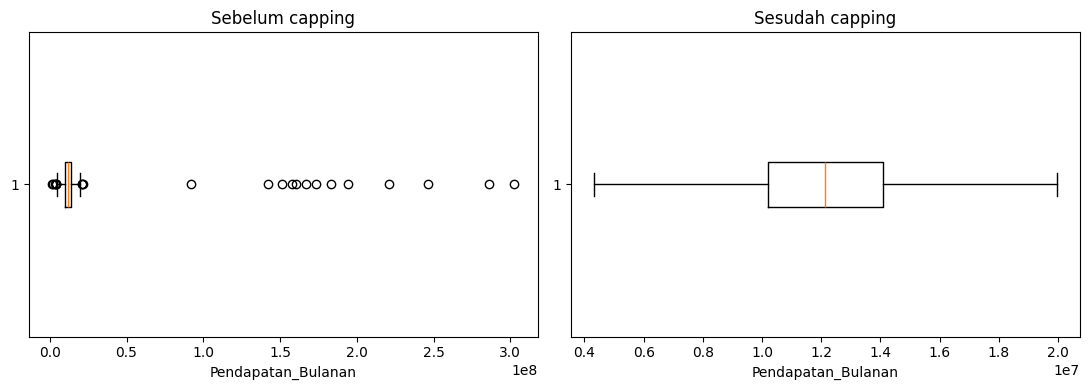

Jumlah baris tetap: 1000


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot(df_m['Pendapatan_Bulanan'], vert=False)
ax[0].set_title('Sebelum capping'); ax[0].set_xlabel('Pendapatan_Bulanan')

Q1, Q3 = df_m['Pendapatan_Bulanan'].quantile([0.25, 0.75])
IQR = Q3 - Q1
batas_bawah, batas_atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f'Q1={Q1:,.0f} | Q3={Q3:,.0f} | IQR={IQR:,.0f}')
print(f'Batas Bawah={batas_bawah:,.0f} | Batas Atas={batas_atas:,.0f}')
n_out = ((df_m['Pendapatan_Bulanan'] < batas_bawah) | (df_m['Pendapatan_Bulanan'] > batas_atas)).sum()
print('Jumlah outlier:', n_out)

df_m['Pendapatan_Bulanan'] = df_m['Pendapatan_Bulanan'].clip(batas_bawah, batas_atas)   # winsorizing

ax[1].boxplot(df_m['Pendapatan_Bulanan'], vert=False)
ax[1].set_title('Sesudah capping'); ax[1].set_xlabel('Pendapatan_Bulanan')
plt.tight_layout(); plt.show()
print('Jumlah baris tetap:', len(df_m))

Jawaban (e.4): Membuang baris outlier (drop rows) berarti kehilangan seluruh informasi nasabah tersebut (skor kredit, status default, dll.), mengecilkan dataset, dan berpotensi menghilangkan pola penting nasabah berpendapatan sangat tinggi bisa saja kelompok yang sah secara bisnis. Bila outlier berkorelasi dengan kelas target, pembuangan juga dapat mengubah distribusi `Status_Default` dan menimbulkan bias seleksi. Pembatasan (capping/winsorizing) mempertahankan semua baris dan hanya meredam pengaruh nilai ekstrem.

## f. Pengkodean Data Kategorikal (Categorical Encoding)

In [11]:
df_e = df_m.copy()

# 1. Ordinal
df_e['Tingkat_Pendidikan_Enc'] = df_e['Tingkat_Pendidikan'].map({'SMA': 1, 'Sarjana': 2, 'Magister': 3})

# 2. Binary
df_e['Pernah_Gagal_Bayar_Lain_Enc'] = df_e['Pernah_Gagal_Bayar_Lain'].map({'Tidak': 0, 'Ya': 1})

# 3. One-Hot (drop_first)
dummies = pd.get_dummies(df_e['Status_Pernikahan'], prefix='Status_Pernikahan', drop_first=True, dtype=int)
df_e = pd.concat([df_e, dummies], axis=1)

# 4. Hapus kolom teks asli & identifier
df_e = df_e.drop(columns=['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain', 'Status_Pernikahan', 'ID_Pelanggan'])
df_e = df_e.rename(columns={'Tingkat_Pendidikan_Enc': 'Tingkat_Pendidikan',
                            'Pernah_Gagal_Bayar_Lain_Enc': 'Pernah_Gagal_Bayar_Lain'})
print(df_e.dtypes)
df_e.head()

Usia                         float64
Pendapatan_Bulanan           float64
Skor_Kredit                  float64
Lama_Bekerja_Thn             float64
Status_Default                 int64
Jumlah_Kartu_Kredit            int64
Tingkat_Pendidikan             int64
Pernah_Gagal_Bayar_Lain        int64
Status_Pernikahan_Menikah      int64
Status_Pernikahan_Single       int64
dtype: object


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Default,Jumlah_Kartu_Kredit,Tingkat_Pendidikan,Pernah_Gagal_Bayar_Lain,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,0,5,3,0,1,0
1,48.0,10514000.0,331.0,20.0,0,3,2,0,1,0
2,34.0,13257000.0,690.0,22.0,0,5,3,0,1,0
3,27.0,10832000.0,576.0,7.0,0,6,2,1,1,0
4,41.0,8295000.0,831.0,15.0,0,4,1,1,0,1


## g. Penskalaan Fitur (Feature Scaling)

In [12]:
X = df_e.drop(columns=['Status_Default'])
y = df_e['Status_Default']

# Variabel numerik (kontinu/hitungan/ordinal). Kolom dummy 0/1 tidak diskalakan agar tetap mudah diinterpretasi.
num_cols = ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn',
            'Jumlah_Kartu_Kredit', 'Tingkat_Pendidikan']
cek3 = ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit']

print('=== SEBELUM standardisasi ===')
display(X[cek3].describe().round(2))

X_scaled = X.copy()
X_scaled[num_cols] = StandardScaler().fit_transform(X[num_cols])

print('=== SESUDAH standardisasi ===')
display(X_scaled[cek3].describe().round(3))

=== SEBELUM standardisasi ===


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1000.00,1000.00,1000.00
mean,40.08,12127496.75,580.51
std,11.58,3062611.27,158.99
min,20.00,4329625.00,300.00
25%,30.00,10192000.00,440.75
50%,41.00,12132000.00,579.00
75%,50.00,14100250.00,722.25
max,59.00,19962625.00,849.00


=== SESUDAH standardisasi ===


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1000.000,1000.000,1000.000
mean,-0.000,0.000,0.000
std,1.001,1.001,1.001
min,-1.735,-2.547,-1.765
25%,-0.871,-0.632,-0.879
50%,0.079,0.001,-0.009
75%,0.857,0.644,0.892
max,1.634,2.560,1.690


Analisis: Setelah Z-score, mean ≈ 0 dan std ≈ 1 (std sampel pandas tampak 1,0005 karena `StandardScaler` memakai ddof=0). Skala fitur kini setara, sehingga algoritma berbasis jarak/gradien (KNN, SVM, regresi logistik) tidak didominasi `Pendapatan_Bulanan` yang bernilai jutaan.

## Simpan Dataset Akhir

In [13]:
final = pd.concat([X_scaled, y], axis=1)
final.to_csv('clean_nasabah_final.csv', index=False)
print('Dimensi akhir:', final.shape)
print('Missing value:', final.isna().sum().sum())
final.head()

Dimensi akhir: (1000, 10)
Missing value: 0


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Jumlah_Kartu_Kredit,Tingkat_Pendidikan,Pernah_Gagal_Bayar_Lain,Status_Pernikahan_Menikah,Status_Pernikahan_Single,Status_Default
0,1.548080,-0.656467,-0.242318,0.007777,1.204949,1.591395,0,1,0,0
1,0.684100,-0.527101,-1.570103,1.054639,0.255423,0.148607,0,1,0,0
2,-0.525473,0.368989,0.689020,1.353742,1.204949,1.591395,0,1,0,0
3,-1.130259,-0.423216,-0.028362,-0.889534,1.679712,0.148607,1,1,0,0
4,0.079313,-1.252008,1.576308,0.306880,0.730186,-1.294181,1,0,1,0
